# Why is IceLab-EDM the worst model for Greece?

**Question.** In the RespiCast summary IceLab-EDM scores about 0.2 for Greece and ranks last. Why?

**What this notebook does**

1. Recomputes the 0.2 from the hub's score file and shows which forecasts cause it.
2. Plots the submitted Greece forecasts against the truth.
3. Reproduces every submitted Greece forecast exactly from the hub's data snapshots.
4. Shows the mechanism inside the GP-EDM fit that produces the bad forecasts.
5. Checks whether the same mechanism is at work in the other countries.
6. Tests candidate fixes on the same forecast dates, and on a replay of the 2025/26 season.

Run from `~/git/Respi` on HPC2N with kernel `test1` (same modules as the weekly run). Hub data are read from a sparse clone in `greece_analysis/hub`.

In [1]:
%matplotlib inline
import sys, os, io, json, warnings, contextlib, subprocess, urllib.request
warnings.filterwarnings('ignore')
sys.path.append('..')

import respi_edm as res
import efm_params as efp
import edm_mp as edm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import norm
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
pandas2ri.activate()

ROOT = 'greece_analysis'
HUB = f'{ROOT}/hub'
HUB_URL = 'https://github.com/european-modelling-hubs/RespiCast-SyndromicIndicators'
SCORES = f'{ROOT}/latest-forecast_scores.csv'
os.makedirs(f'{ROOT}/results', exist_ok=True); os.makedirs(f'{ROOT}/figs', exist_ok=True)

if not os.path.isdir(HUB):
    subprocess.run(['git', 'clone', '--quiet', '--depth', '1', '--filter=blob:none', '--sparse', HUB_URL + '.git', HUB], check=True)
    subprocess.run(['git', '-C', HUB, 'sparse-checkout', 'set', 'model-output', 'target-data', 'supporting-files'], check=True)
if not os.path.exists(SCORES):
    urllib.request.urlretrieve(HUB_URL + '/blob/main/model-evaluation/latest-forecast_scores.csv?raw=true', SCORES)
print('hub commit:', subprocess.run(['git', '-C', HUB, 'log', '-1', '--format=%h %ad', '--date=short'], capture_output=True, text=True).stdout.strip())

LOC, TARGET, MODEL = 'GR', 'ILI incidence', 'IceLab-EDM'
SEASON_START = '2026-08-19'   # first IceLab-EDM submission of the 2026/27 season
summary = {}                  # key numbers, written to greece_analysis/results/summary.json at the end

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
pd.set_option('display.precision', 3)

# figure style: one accent per entity, everything else grey
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
C_ICE, C_FIX, C_LAST, C_OTHER = '#2a78d6', '#eb6834', '#1baf7a', '#a3a29c'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': MUTED, 'text.color': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 9, 'lines.linewidth': 2, 'figure.dpi': 110, 'legend.frameon': False,
})

def show(fig, name):
    fig.savefig(f'{ROOT}/figs/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

hub commit: 57a4a15 2026-10-08


## 1. Where the 0.2 comes from

The hub scores every forecast with the weighted interval score (WIS, lower is better) and converts it to a `rank_score` between 0 and 1. The check below shows that `rank_score` is a min-max scaling of WIS across the models that forecast the same target: 1 for the best model, 0 for the worst.

In [2]:
sc = pd.read_csv(SCORES)
sc['model'] = sc.team_id + '-' + sc.model_id
wis_sc = sc[sc.metric == 'WIS']
gr = wis_sc[(wis_sc.location == LOC) & (wis_sc.target == TARGET) & (wis_sc.origin_date >= SEASON_START)].copy()

grp = gr.groupby(['origin_date', 'horizon']).value_absolute
minmax = (grp.transform('max') - gr.value_absolute) / (grp.transform('max') - grp.transform('min'))
print('max |rank_score - (worst - WIS)/(worst - best)| over Greece rows:', f'{(minmax - gr.rank_score).abs().max():.2e}')

by_model = gr.groupby('model').agg(
    rank_score=('rank_score', 'mean'), mean_WIS=('value_absolute', 'mean'),
    times_worst=('rank_score', lambda s: int((s == 0).sum())), n_forecasts=('rank_score', 'size'),
).sort_values('rank_score')
ice = gr[gr.model == MODEL]
summary['gr_rank_score'] = float(by_model.loc[MODEL, 'rank_score'])
summary['gr_n_scored'] = int(len(ice))
summary['gr_times_worst'] = int((ice.rank_score == 0).sum())
summary['gr_n_models'] = int(len(by_model))
summary['gr_mean_wis'] = float(by_model.loc[MODEL, 'mean_WIS'])
print(f"{MODEL}: mean rank_score {summary['gr_rank_score']:.3f} over {len(ice)} scored Greece forecasts "
      f"(origin dates {ice.origin_date.min()} to {ice.origin_date.max()}); worst model in {summary['gr_times_worst']} of them")
by_model

max |rank_score - (worst - WIS)/(worst - best)| over Greece rows: 1.11e-16
IceLab-EDM: mean rank_score 0.202 over 18 scored Greece forecasts (origin dates 2026-08-19 to 2026-09-30); worst model in 10 of them


,rank_score,mean_WIS,times_worst,n_forecasts
model,,,,
IceLab-EDM,0.202,174.621,10,18
QMUL-SEIR_agumented,0.398,122.299,7,18
QMUL-SEIR,0.616,87.703,0,18
ItaLuxColab-EpiEKF,0.654,64.042,3,22
QMUL-ARIMA,0.690,69.004,0,18
ECDC-SARIMA,0.737,61.059,0,17
safinea-PRFM,0.770,49.106,1,22
ItaLuxColab-EpiNetEKF,0.785,48.180,0,22
respicast-quantileBaseline,0.801,51.174,0,22


In [3]:
others = gr[gr.model != MODEL]
by_h = pd.DataFrame({
    'IceLab-EDM WIS': ice.groupby('horizon').value_absolute.mean(),
    'median other model WIS': others.groupby(['horizon', 'model']).value_absolute.mean().groupby('horizon').median(),
    'IceLab-EDM rank_score': ice.groupby('horizon').rank_score.mean(),
    'n scored': ice.groupby('horizon').size(),
})
by_h['WIS ratio'] = by_h['IceLab-EDM WIS'] / by_h['median other model WIS']
summary['gr_by_horizon'] = by_h.reset_index().to_dict('records')
by_h

,IceLab-EDM WIS,median other model WIS,IceLab-EDM rank_score,n scored,WIS ratio
horizon,,,,,
1,54.168,36.664,0.507,6,1.477
2,260.866,53.535,0.042,5,4.873
3,214.586,59.052,0.046,4,3.634
4,218.499,63.694,0.064,3,3.430


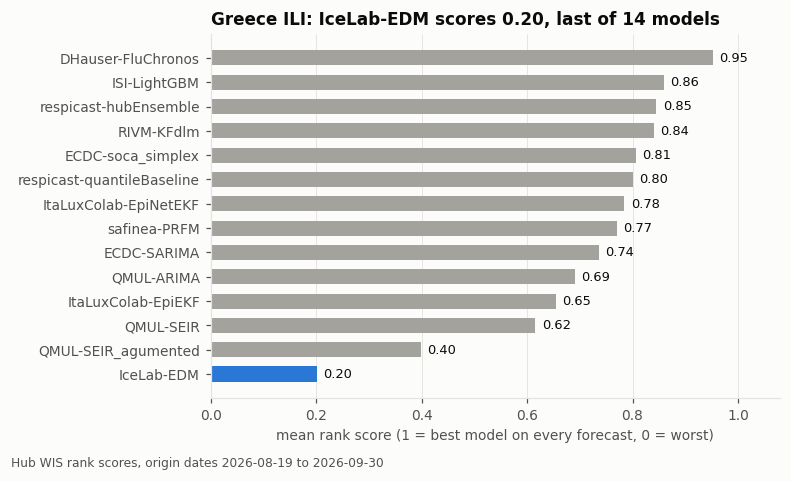

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
bm = by_model.sort_values('rank_score', ascending=False)
ax.barh(bm.index, bm.rank_score, height=0.62, color=[C_ICE if m == MODEL else C_OTHER for m in bm.index])
for y, v in enumerate(bm.rank_score):
    ax.text(v + 0.012, y, f'{v:.2f}', va='center', fontsize=8.5, color=INK)
ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.grid(axis='y', visible=False)
ax.set_xlabel('mean rank score (1 = best model on every forecast, 0 = worst)')
ax.set_title(f"Greece ILI: IceLab-EDM scores {summary['gr_rank_score']:.2f}, last of {len(bm)} models")
fig.text(0.01, -0.02, f'Hub WIS rank scores, origin dates {ice.origin_date.min()} to {ice.origin_date.max()}', fontsize=8, color=MUTED)
plt.tight_layout(); show(fig, '1_greece_rank_score_by_model')

The 1-week-ahead forecasts are roughly in line with the other models. Weeks 2 to 4 carry the problem: there the WIS is about four times the median model's.

## 2. The submitted forecasts against the truth

In [5]:
fw = pd.read_csv(f'{HUB}/supporting-files/forecasting_weeks.csv')
truth_all = pd.read_csv(f'{HUB}/target-data/latest-ILI_incidence.csv')
truth = truth_all[truth_all.location == LOC].set_index('truth_date').value.sort_index()

def horizon_dates(od):
    """(date of the last observation available at submission, [target dates for horizons 1..4])"""
    w = fw[fw.origin_date == od].set_index('horizon').target_end_date
    return w[0], [w[h] for h in (1, 2, 3, 4)]

def quantile_table(model, od, loc=LOC, target=TARGET):
    d = pd.read_csv(f'{HUB}/model-output/{model}/{od}-{model}.csv')
    d = d[(d.location == loc) & (d.target == target) & (d.output_type == 'quantile')].copy()
    d['q'] = d.output_type_id.astype(float).round(3)
    return d.pivot_table(index='target_end_date', columns='q', values='value')

origins = sorted(f[:10] for f in os.listdir(f'{HUB}/model-output/{MODEL}') if f.endswith('.csv') and f[:10] >= SEASON_START)
rows = []
for od in origins:
    q = quantile_table(MODEL, od)
    for h, (ted, r) in enumerate(q.iterrows(), start=1):
        rows.append(dict(origin_date=od, horizon=h, target_end_date=ted, median=r[0.5], q2_5=r[0.025], q97_5=r[0.975], truth=truth.get(ted, np.nan)))
sub_gr = pd.DataFrame(rows)
sub_gr['abs_error'] = (sub_gr['median'] - sub_gr.truth).abs()
scored_sub = sub_gr.dropna(subset=['truth'])
print('Scored Greece forecasts by horizon (ILI cases per 100,000):')
print(scored_sub.groupby('horizon').agg(n=('truth', 'size'), mean_forecast_median=('median', 'mean'), mean_observed=('truth', 'mean'), mean_abs_error=('abs_error', 'mean')).round(1))
print(f"\nGreece: mean of the whole series since 2022 = {truth.mean():.0f}, mean of the last 12 weeks = {truth.tail(12).mean():.0f}")
summary['gr_series_mean'] = float(truth.mean()); summary['gr_recent_mean'] = float(truth.tail(12).mean())
summary['gr_median_by_h'] = {int(k): float(v) for k, v in sub_gr.groupby('horizon')['median'].mean().round(1).items()}

Scored Greece forecasts by horizon (ILI cases per 100,000):
         n  mean_forecast_median  mean_observed  mean_abs_error
horizon                                                        
1        6                 300.6          304.9            90.3
2        5                 792.7          309.7           483.1
3        4                 678.9          284.2           394.7
4        3                 679.8          276.8           403.0

Greece: mean of the whole series since 2022 = 668, mean of the last 12 weeks = 279


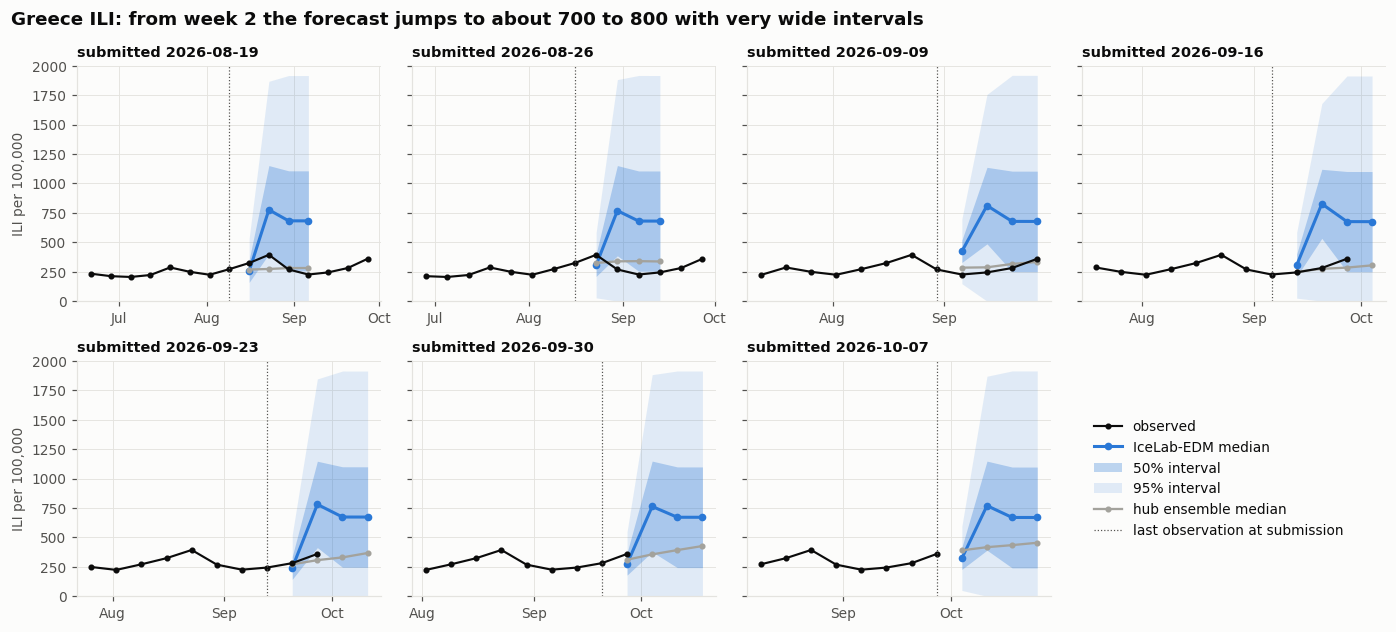

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.8), sharey=True)
for ax, od in zip(axes.flat, origins):
    h0, teds = horizon_dates(od)
    q = quantile_table(MODEL, od); x = pd.to_datetime(q.index)
    ax.fill_between(x, q[0.025], q[0.975], color=C_ICE, alpha=0.13, lw=0)
    ax.fill_between(x, q[0.25], q[0.75], color=C_ICE, alpha=0.30, lw=0)
    ax.plot(x, q[0.5], color=C_ICE, marker='o', ms=4)
    try:
        e = quantile_table('respicast-hubEnsemble', od)
        ax.plot(pd.to_datetime(e.index), e[0.5], color=C_OTHER, marker='o', ms=3, lw=1.5)
    except Exception:
        pass
    t = truth[truth.index >= (pd.Timestamp(h0) - pd.Timedelta(weeks=7)).strftime('%Y-%m-%d')]
    ax.plot(pd.to_datetime(t.index), t.values, color=INK, lw=1.4, marker='o', ms=3)
    ax.axvline(pd.Timestamp(h0), color=MUTED, lw=0.8, ls=':')
    ax.set_title(f'submitted {od}', fontsize=9.5)
    ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.set_ylim(0, 2000)
axes[0, 0].set_ylabel('ILI per 100,000'); axes[1, 0].set_ylabel('ILI per 100,000')
lg = axes.flat[-1]; lg.axis('off')
lg.plot([], [], color=INK, marker='o', ms=3, lw=1.4, label='observed')
lg.plot([], [], color=C_ICE, marker='o', ms=4, label='IceLab-EDM median')
lg.fill_between([], [], [], color=C_ICE, alpha=0.30, lw=0, label='50% interval')
lg.fill_between([], [], [], color=C_ICE, alpha=0.13, lw=0, label='95% interval')
lg.plot([], [], color=C_OTHER, marker='o', ms=3, lw=1.5, label='hub ensemble median')
lg.plot([], [], color=MUTED, lw=0.8, ls=':', label='last observation at submission')
lg.legend(loc='center left', fontsize=9)
fig.suptitle('Greece ILI: from week 2 the forecast jumps to about 700 to 800 with very wide intervals', x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); show(fig, '2_greece_forecasts_vs_observed')

Every submission since August has the same shape: a reasonable first week, then a jump to about 770 to 830 in week 2 and about 675 in weeks 3 and 4, with a 95% interval from 0 to about 1,900. Observed incidence was between 226 and 394.

## 3. Reproducing the submitted forecasts exactly

`production_inputs` and `fit_production` below are copies of the logic in `respi_edm.run_analysis`, applied to the hub's data snapshot from the Friday before each origin date. If the copy is faithful, it returns the submitted numbers.

In [7]:
ro.r("""
suppressMessages(library(GPEDM))

# Production model, as in respi_edm.run_analysis: variable-timestep GP-EDM,
# 4 forecasts requested as time gaps 1..4 after the last row.
fit_prod <- function(d, E) {
  lags <- makelags(data=d, y="X", time="Time", E=E, tau=1, vtimestep=T)
  dd <- cbind(d, lags)
  m <- fitGP(data=dd, y="X", x=colnames(lags), time="Time")
  fore <- makelags(data=d, y="X", time="Time", E=E, tau=1, vtimestep=T, forecast=T, Tdiff_fore=c(1,2,3,4))
  p <- predict(m, newdata=fore)$outsampresults
  tr <- dd[complete.cases(dd), ]
  list(predmean=p$predmean, predsd=p$predsd, pars=m$pars, xsds=m$scaling$xsds,
       ymean=m$scaling$ymeans, ysd=m$scaling$ysds, ntrain=nrow(tr),
       gap1=tr[, "Tdiff_1"], ytrain=tr[, "X"], ttrain=tr[, "Time"], fore_gap1=fore[, "Tdiff_1"])
}

# Plain GP on a design matrix built in Python (used for the candidate fixes in section 6)
fit_design <- function(tr, fo, xn) {
  m <- fitGP(data=tr, y="X", x=xn, time="Time")
  p <- predict(m, newdata=fo)$outsampresults
  list(predmean=p$predmean, predsd=p$predsd, pars=m$pars)
}
""")

def R(name, *args):
    r = ro.r[name](*args)
    out = {k: np.asarray(v, dtype=float) for k, v in zip(r.names, list(r))}
    return {k: np.where(v <= -2147483648, np.nan, v) for k, v in out.items()}   # R's NA

def production_inputs(df_sel):
    """Copy of the data preparation in respi_edm.run_analysis.
    Returns the year x week grid as a vector, first/last index holding data, and the embedding dimension E."""
    with contextlib.redirect_stdout(io.StringIO()):
        weeks, years, unique_weeks, unique_years, row_idx, col_idx, datatmp = res.extract_weekly_data_ari(df_sel, 0, 52, 2027)
        linear_index, row, col, all_years, nweeks = edm.make_linear_index(years, weeks, 0)
        testData = np.full((len(all_years), nweeks), np.nan)
        testData[row_idx, col_idx] = datatmp
        vector = testData.flatten()
        flat_idx = np.ravel_multi_index((row_idx, col_idx), testData.shape)
        MI, tau, emb_len = efp.find_best_tau(vector, 8, 3, mi_threshold=np.nan, mi_fraction=np.nan)
        dims, fnn_fracs, best_dim, n_pts = efp.fnn_from_sparse_embeddings(vector, tau, max_dim=8)
    return vector, int(min(flat_idx)), int(max(flat_idx)), int(best_dim)

def fit_production(x, E, nan_at=20):
    """Production fit on series x. nan_at=20 is the production line `df1.iloc[20,1] = np.nan`."""
    df1 = pd.DataFrame({'Time': np.arange(len(x)), 'X': np.asarray(x, dtype=float)})
    if nan_at is not None:
        df1.iloc[nan_at, 1] = np.nan
    r = R('fit_prod', pandas2ri.py2rpy(df1), E)
    r['phi_gap'] = r['pars'][E]            # inverse length scale of the first time-gap input (Tdiff_1)
    r['sd_gap'] = r['xsds'][E]             # its standard deviation in the training rows
    # kernel weight left between a forecast row at gap h and training rows at gap 1
    r['weight'] = np.exp(-r['phi_gap'] * ((np.arange(1, 5) - 1) / r['sd_gap']) ** 2)
    return r

def snapshot_series(od, target, loc):
    """The location's series as published in the hub snapshot of the Friday before origin date od."""
    sd = (pd.Timestamp(od) - pd.Timedelta(days=5)).strftime('%Y-%m-%d')
    for src in ('ERVISS', 'FluID'):
        f = f"{HUB}/target-data/{src}/snapshots/{sd}-{target.split()[0]}_incidence.csv"
        if os.path.exists(f):
            d = pd.read_csv(f); d = d[d.location == loc]
            if len(d):
                return d
    return None

rows = []
for od in origins:
    d = snapshot_series(od, TARGET, LOC)
    vector, a, b, E = production_inputs(d)
    x_prod = vector[a:b]                       # production: vector[minIdx:maxIdx-backPts], backPts = 0
    r = fit_production(x_prod, E)
    submitted = sub_gr[sub_gr.origin_date == od].sort_values('horizon')['median'].to_numpy()
    dates = np.sort(d.truth_date.to_numpy())
    rows.append(dict(origin_date=od, E=E, max_abs_diff_vs_submitted=np.abs(np.clip(r['predmean'], 0, None) - submitted).max(),
                     latest_obs_date=dates[-1], latest_obs=vector[b], last_value_given_to_model=x_prod[-1],
                     h1=r['predmean'][0], h2=r['predmean'][1], h3=r['predmean'][2], h4=r['predmean'][3]))
repro = pd.DataFrame(rows)
summary['repro_max_abs_diff'] = float(repro.max_abs_diff_vs_submitted.max())
print(f"largest difference between the reproduction and the submitted medians: {summary['repro_max_abs_diff']:.1e}")
repro

largest difference between the reproduction and the submitted medians: 2.6e-11


,origin_date,E,max_abs_diff_vs_submitted,latest_obs_date,latest_obs,last_value_given_to_model,h1,h2,h3,h4
0,2026-08-19,3,2.291e-11,2026-08-09,271.9,224.2,255.319,775.977,682.259,682.036
1,2026-08-26,3,1.148e-11,2026-08-16,324.0,271.9,305.199,768.578,680.337,680.128
2,2026-09-09,3,9.663e-12,2026-08-30,269.0,393.6,423.123,811.647,677.480,677.166
3,2026-09-16,3,1.791e-11,2026-09-06,226.2,269.0,305.017,826.813,675.646,675.294
4,2026-09-23,3,2.612e-11,2026-09-13,244.2,226.2,240.682,780.719,673.494,673.243
5,2026-09-30,3,4.661e-12,2026-09-20,281.6,244.2,274.188,763.200,671.507,671.293
6,2026-10-07,3,2.524e-11,2026-09-27,360.0,281.6,322.548,769.909,669.763,669.530


The reproduction matches all submissions to about 1e-11, so the analysis below is of the model that was actually submitted.

The table also shows a second, separate problem: `last_value_given_to_model` is not the latest observation. The production slice `vector[minIdx:maxIdx-backPts]` has an exclusive end, so the newest data point is dropped. The model's last row is one week older than the latest truth, and its "gap 1" forecast is a forecast of the week that is already observed, submitted as horizon 1. This affects every country, not only Greece.

## 4. The mechanism

The production code makes the 4-week forecast with GPEDM's variable-timestep method: the time gap between a value and its lagged predictors (`Tdiff`) is an extra GP input, and the forecast rows ask for gaps 1, 2, 3 and 4 (`Tdiff_fore=c(1,2,3,4)`). The GP can only know what a gap of 2 to 4 weeks does if it has seen such gaps in training.

In [8]:
od = '2026-09-09'
d = snapshot_series(od, TARGET, LOC)
vector, a, b, E = production_inputs(d)
x_prod = vector[a:b]
r = fit_production(x_prod, E)
dates = np.sort(d.truth_date.to_numpy())            # Greece has no missing weeks, so dates align with vector[a:b+1]
assert len(dates) == b - a + 1 and not np.isnan(vector[a:b + 1]).any()

print(f'Origin date {od}, Greece, E = {E}')
print(f"training rows: {int(r['ntrain'][0])}; time gap to the first lag: "
      + ', '.join(f'{int(n)} rows with gap {int(g)}' for g, n in zip(*np.unique(r['gap1'], return_counts=True))))
print('gaps requested for the forecast rows:', r['fore_gap1'].astype(int).tolist())
gi = int(r['ttrain'][r['gap1'] > 1][0])
print(f'the only gap-2 row: target week {dates[gi]} (value {x_prod[gi]:.0f}), created by the production line df1.iloc[20,1] = np.nan')
print()
names = [f'X_{k+1}' for k in range(E)] + [f'Tdiff_{k+1}' for k in range(E)]
print('fitted inverse length scales (phi):', dict(zip(names, np.round(r['pars'][:2 * E], 4))))
print(f"sd of Tdiff_1 in training = {r['sd_gap']:.4f} weeks, so one extra week of gap is {1 / r['sd_gap']:.1f} standard deviations")
print('kernel weight left at gap 1, 2, 3, 4:', np.array2string(r['weight'], precision=4, suppress_small=True))
print()
print(f"forecast means  h1..h4: {np.round(r['predmean'], 1)}   series mean used by the GP: {r['ymean'][0]:.1f}")
print(f"forecast sds    h1..h4: {np.round(r['predsd'], 1)}   series sd: {r['ysd'][0]:.1f}")
summary['mechanism'] = dict(origin_date=od, E=E, ntrain=int(r['ntrain'][0]), n_gap2=int((r['gap1'] > 1).sum()), gap2_week=str(dates[gi]),
                            gap2_value=float(x_prod[gi]), phi_gap=float(r['phi_gap']), sd_gap=float(r['sd_gap']), weight=r['weight'].tolist(),
                            predmean=r['predmean'].tolist(), predsd=r['predsd'].tolist(), ymean=float(r['ymean'][0]), ysd=float(r['ysd'][0]))

Origin date 2026-09-09, Greece, E = 3
training rows: 214; time gap to the first lag: 213 rows with gap 1, 1 rows with gap 2
gaps requested for the forecast rows: [1, 2, 3, 4]
the only gap-2 row: target week 2022-11-20 (value 885), created by the production line df1.iloc[20,1] = np.nan

fitted inverse length scales (phi): {'X_1': 0.1977, 'X_2': 0.9352, 'X_3': 0.1256, 'Tdiff_1': 0.0282, 'Tdiff_2': 0.0, 'Tdiff_3': 0.0}
sd of Tdiff_1 in training = 0.0682 weeks, so one extra week of gap is 14.7 standard deviations
kernel weight left at gap 1, 2, 3, 4: [1.     0.0023 0.     0.    ]

forecast means  h1..h4: [423.1 811.6 677.5 677.2]   series mean used by the GP: 677.2
forecast sds    h1..h4: [140.2 481.9 633.1 633.1]   series sd: 402.9


This is the cause.

- Greece reports every week, so all training rows have gap 1. The production code blanks out one observation (index 20) to make the variable-timestep method run, which creates exactly one row with gap 2 and none with gaps 3 or 4.
- With a single exception, `Tdiff_1` is constant, so its standard deviation is 0.07 weeks. After GPEDM standardises the inputs, a forecast row at gap 2 sits about 15 standard deviations away from the training data, and gaps 3 and 4 sit 29 and 44 away.
- In the Greece fit the optimiser gives `Tdiff_1` a non-zero inverse length scale. The kernel weight between the week-2 to week-4 forecast rows and the training data is then effectively zero, and a GP with nothing nearby returns its prior: the mean of the whole series (677) with the spread of the whole series.
- The week-2 forecast is not the prior mean only because it sits next to the single gap-2 row, a week from November 2022 during the winter rise.

The next cell tests this directly. If the week 2 to 4 forecasts hinge on that one artificial row, moving the blanked observation should change them.

In [9]:
rows = []
for pos in [None, 10, 20, 30, 50, 80, 110, 140, 170, 200]:
    try:
        rr = fit_production(x_prod, E, nan_at=pos)
        rows.append(dict(blanked_index=pos, blanked_week=dates[pos] if pos is not None else 'none',
                         two_week_change_at_gap_row=(x_prod[pos + 1] - x_prod[pos - 1]) if pos is not None else np.nan,
                         phi_gap=rr['phi_gap'], weight_h2=rr['weight'][1],
                         h1=rr['predmean'][0], h2=rr['predmean'][1], h3=rr['predmean'][2], h4=rr['predmean'][3], sd_h4=rr['predsd'][3]))
    except Exception as e:
        rows.append(dict(blanked_index=pos, blanked_week='none' if pos is None else dates[pos], h1=np.nan))
nan_exp = pd.DataFrame(rows)
summary['nan_experiment'] = json.loads(nan_exp.to_json(orient='records'))
nan_exp

,blanked_index,blanked_week,two_week_change_at_gap_row,phi_gap,weight_h2,h1,h2,h3,h4,sd_h4
0,NaN,none,NaN,9.805e-76,0.000,NaN,NaN,NaN,NaN,NaN
1,10.0,2022-09-04,-68.7,4.694e-53,1.000,401.995,401.995,401.995,401.995,153.241
2,20.0,2022-11-13,330.6,2.821e-02,0.002,423.123,811.647,677.480,677.166,633.098
3,30.0,2023-01-22,-723.4,2.430e-03,0.593,399.544,505.793,635.906,670.880,651.697
4,50.0,2023-06-11,-10.7,2.407e-238,1.000,403.160,403.160,403.160,403.160,153.619
5,80.0,2024-01-07,-1021.5,2.646e-03,0.566,408.499,451.125,590.432,658.485,706.173
6,110.0,2024-08-04,-132.4,1.248e-216,1.000,404.807,404.807,404.807,404.807,153.118
7,140.0,2025-03-02,-133.8,3.572e-05,0.992,426.033,427.875,433.438,442.468,271.342
8,170.0,2025-09-28,275.4,3.083e-04,0.936,397.891,580.742,752.673,858.256,411.450
9,200.0,2026-04-26,-267.7,2.603e-04,0.946,403.982,257.481,169.862,164.885,423.036


Same data, same model, same origin date: only the position of the artificially blanked week changes, and the week 2 to 4 forecasts move by hundreds. With no blanked week the method does not return usable numbers at all, which is why the line was added. The horizon behaviour of the production model is decided by one arbitrary training row.

## 5. Is this only Greece?

The cell below refits the production model for every series IceLab-EDM submitted since August and records how the fit treats the time gap.

In [10]:
rows = []
for od in origins:
    sub = pd.read_csv(f'{HUB}/model-output/{MODEL}/{od}-{MODEL}.csv')
    med = sub[sub.output_type == 'median']
    for (tgt, loc), g in med.groupby(['target', 'location']):
        try:
            d = snapshot_series(od, tgt, loc)
            vector, a, b, E = production_inputs(d)
            x = vector[a:b]
            r = fit_production(x, E)
            m = r['predmean']
            rows.append(dict(origin_date=od, target=tgt, location=loc, E=E, n=len(x), missing_weeks=int(np.isnan(x).sum()),
                             rows_gap_gt1=int((r['gap1'] > 1).sum()), phi_gap=r['phi_gap'], sd_gap=r['sd_gap'],
                             w2=r['weight'][1], w3=r['weight'][2], w4=r['weight'][3],
                             max_abs_diff=np.abs(np.clip(m, 0, None) - g.sort_values('horizon').value.to_numpy()).max(),
                             h1=m[0], h2=m[1], h3=m[2], h4=m[3], sd_h1=r['predsd'][0], sd_h4=r['predsd'][3],
                             series_mean=r['ymean'][0], series_sd=r['ysd'][0], last_value=x[~np.isnan(x)][-1]))
        except Exception as e:
            rows.append(dict(origin_date=od, target=tgt, location=loc, error=str(e)[:60]))
mech = pd.DataFrame(rows)
ok = mech[mech.max_abs_diff.notna()].copy()
not_rep = ok[ok.max_abs_diff >= 1e-6 * np.maximum(1, ok.h1.abs())]
print('series-weeks where the refit does not match the submitted medians to 1e-6 (left out below):')
print(not_rep.assign(relative_diff=not_rep.max_abs_diff / np.maximum(1, not_rep.h1.abs()))[['origin_date', 'target', 'location', 'E', 'missing_weeks', 'relative_diff']].to_string(index=False))
ok['reproduced'] = ok.max_abs_diff < 1e-6 * np.maximum(1, ok.h1.abs())
print(f"{len(mech)} submitted series-weeks; refit succeeded for {len(ok)}; reproduced the submitted medians exactly for {int(ok.reproduced.sum())}")
ok = ok[ok.reproduced].copy()
spread = ok[['h1', 'h2', 'h3', 'h4']].max(axis=1) - ok[['h1', 'h2', 'h3', 'h4']].min(axis=1)
ok['behaviour'] = np.where(spread < 1e-6 * np.maximum(1, ok.h1.abs()), 'same number for all 4 weeks',
                  np.where(ok.w2 < 0.5, 'collapses to long-run mean from week 2', 'changes with horizon'))
print(ok.behaviour.value_counts().to_string())
summary['behaviour_counts'] = {k: int(v) for k, v in ok.behaviour.value_counts().items()}
summary['n_series_weeks'] = int(len(ok))

series-weeks where the refit does not match the submitted medians to 1e-6 (left out below):
origin_date        target location  E  missing_weeks  relative_diff
 2026-08-19 ILI incidence       MT  4             20          0.037
 2026-08-19 ILI incidence       SI  5              0          0.140
 2026-08-26 ILI incidence       LU  3             16          0.010
 2026-08-26 ILI incidence       MT  4             20          0.033
 2026-09-16 ILI incidence       SI  6              0          0.274
 2026-09-23 ILI incidence       HR  5             29          0.051
 2026-09-23 ILI incidence       SI  5              0          0.268
 2026-09-30 ILI incidence       MT  3             20          0.013
 2026-10-07 ILI incidence       MT  4             20          0.011
181 submitted series-weeks; refit succeeded for 181; reproduced the submitted medians exactly for 172
behaviour
same number for all 4 weeks               95
changes with horizon                      70
collapses to long-run mean

In [11]:
ok['retained'] = ok[['w2', 'w3', 'w4']].mean(axis=1)
ok['gap_to_mean_sd'] = (ok.series_mean - ok.last_value) / ok.series_sd
per_series = ok.groupby(['target', 'location']).agg(
    submissions=('origin_date', 'size'), E=('E', 'median'), missing_weeks=('missing_weeks', 'median'),
    info_retained_h2to4=('retained', 'mean'), same_for_all_weeks=('behaviour', lambda s: (s == 'same number for all 4 weeks').mean()),
    collapses=('behaviour', lambda s: (s == 'collapses to long-run mean from week 2').mean()),
    level_below_mean_in_sd=('gap_to_mean_sd', 'mean'), sd_h4_over_sd_h1=('sd_h4', 'mean'))
per_series['sd_h4_over_sd_h1'] = ok.groupby(['target', 'location']).apply(lambda g: (g.sd_h4 / g.sd_h1).mean())
ice_all = wis_sc[(wis_sc.model == MODEL) & (wis_sc.origin_date >= SEASON_START)]
per_series['rank_score_h1'] = ice_all[ice_all.horizon == 1].groupby(['target', 'location']).rank_score.mean()
per_series['rank_score_h2to4'] = ice_all[ice_all.horizon >= 2].groupby(['target', 'location']).rank_score.mean()
per_series['n_scored_h2to4'] = ice_all[ice_all.horizon >= 2].groupby(['target', 'location']).size()
per_series = per_series.sort_values('info_retained_h2to4')
per_series.to_csv(f'{ROOT}/results/per_series_mechanism.csv')
per_series.round(2)

submissions    E  missing_weeks  info_retained_h2to4  same_for_all_weeks  collapses  level_below_mean_in_sd  sd_h4_over_sd_h1  rank_score_h1  rank_score_h2to4  n_scored_h2to4
target        location                                                                                                                                                                                
ILI incidence GR                  7  3.0            0.0                 0.00                0.00        1.0                    1.00              4.48           0.51              0.05            12.0
ARI incidence ES                  6  3.0            0.0                 0.33                0.00        0.0                    1.13              5.91           0.36              0.21            11.0
              DE                  7  3.0            0.0                 0.55                0.00        0.0                    1.10              4.10           0.23              0.26            12.0
              BE                  7  3.0            0.0                 0.68                0.00        0.0                    1.24              3.29           0.48              0.56            12.0
              IS                  6  3.0            0.0                 0.70                0.00        0.0                    0.81              3.66           0.37              0.40            12.0
ILI incidence IS                  6  4.0            7.0                 0.75                0.00        0.0                    0.62              5.89           0.73              0.56            12.0
              HU                  7  2.0           63.0                 0.80                0.00        0.0                    1.03              3.54           0.61              0.76            12.0
ARI incidence HU                  7  3.0           63.0                 0.80                0.00        0.0                    1.58              2.52           0.54              0.81            12.0
              EE                  5  3.0           11.0                 0.88                0.60        0.0                    0.53              1.11           0.70              0.52             7.0
ILI incidence IE                  7  4.0            1.0                 0.90                0.00        0.0                    0.60              4.94           0.61              0.71            12.0
ARI incidence IE                  7  3.0            0.0                 0.92                0.71        0.0                    0.89              1.84           0.22              0.29            12.0
ILI incidence EE                  5  3.0           10.0                 0.97                0.00        0.0                    1.17              1.15           0.57              0.90             7.0
              NO                  7  3.0           52.0                 0.99                0.57        0.0                    0.71              1.85           0.71              0.65            12.0
ARI incidence NL                  7  2.0           52.0                 1.00                0.29        0.0                    1.09              1.00           0.51              0.55            12.0
              BG                  7  3.0            3.0                 1.00                1.00        0.0                    1.12              1.00           0.14              0.42            12.0
ILI incidence RO                  2  8.0           19.5                 1.00                1.00        0.0                    0.55              1.00           0.00              0.00             1.0
              MT                  2  3.5           20.0                 1.00                1.00        0.0                   -0.76              1.00           0.57              0.56            11.0
              FI                  1  5.0            5.0                 1.00                1.00        0.0                    0.14              1.00            NaN               NaN             NaN
              LU                  5  3.0    

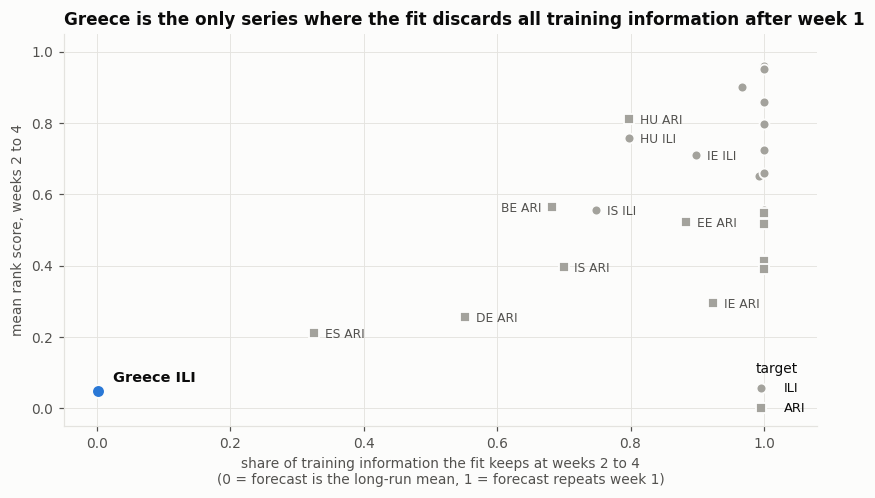

In [12]:
ps = per_series.dropna(subset=['rank_score_h2to4']).reset_index()
ps = ps[ps.n_scored_h2to4 >= 6]
fig, ax = plt.subplots(figsize=(7.6, 4.6))
for tgt, mk in (('ILI incidence', 'o'), ('ARI incidence', 's')):
    s = ps[(ps.target == tgt) & ~((ps.location == LOC) & (ps.target == TARGET))]
    ax.scatter(s.info_retained_h2to4, s.rank_score_h2to4, s=42, marker=mk, color=C_OTHER, edgecolor=SURFACE, linewidth=1.2, label=tgt.split()[0], zorder=3)
g = ps[(ps.location == LOC) & (ps.target == TARGET)]
ax.scatter(g.info_retained_h2to4, g.rank_score_h2to4, s=70, marker='o', color=C_ICE, edgecolor=SURFACE, linewidth=1.2, zorder=4)
ax.annotate('Greece ILI', (g.info_retained_h2to4.iloc[0], g.rank_score_h2to4.iloc[0]), xytext=(10, 6), textcoords='offset points', fontsize=9.5, fontweight='bold')
for _, r_ in ps[(ps.info_retained_h2to4 < 0.95) & ~((ps.location == LOC) & (ps.target == TARGET))].iterrows():
    on_left = (r_.location, r_.target) == ('BE', 'ARI incidence')      # keeps this label clear of its neighbour
    ax.annotate(f"{r_.location} {r_.target.split()[0]}", (r_.info_retained_h2to4, r_.rank_score_h2to4), xytext=(-7 if on_left else 7, -3),
                ha='right' if on_left else 'left', textcoords='offset points', fontsize=8, color=MUTED)
ax.set_xlim(-0.05, 1.08); ax.set_ylim(-0.05, 1.05)
ax.set_xlabel('share of training information the fit keeps at weeks 2 to 4\n(0 = forecast is the long-run mean, 1 = forecast repeats week 1)')
ax.set_ylabel('mean rank score, weeks 2 to 4')
ax.set_title('Greece is the only series where the fit discards all training information after week 1')
ax.legend(title='target', loc='lower right', fontsize=8.5)
plt.tight_layout(); show(fig, '3_information_retained_vs_rank_score')

The same weakness is present in every series, and it shows up in three ways.

- **Same number for all four weeks (about half of the series-weeks):** the optimiser sets the time-gap length scale to zero, so the gap is ignored and all four horizons receive the same number with the same uncertainty. The submission is the 1-week forecast repeated four times. That scores acceptably in a flat summer, but it is not a 4-week forecast and its intervals do not widen with horizon.
- **Changes with horizon:** the gap has some influence, learned from the one artificial gap row (or from real reporting gaps in series such as HU, NO and NL). ES and DE ARI lose most of the training information by weeks 3 and 4 and also score poorly there.
- **Collapses from week 2:** only Greece, on every submission since August.

Greece is the worst series because the collapse is complete from week 2. The prior it collapses to is the long-run mean, which is dominated by winter peaks and is about 2.4 times the recent summer level.

## 6. Candidate fixes, tested on the same forecast dates

Four variants, all with the same data snapshots, the same E and the same GP package:

- **A. As submitted.**
- **B. Keep the latest observation.** Production model with the slice corrected to include the newest data point. Nothing else changes.
- **C. Horizon as an input.** One GP trained on real examples of every horizon: rows are (the last E values known at time t-h, h) with target the value at t, for h = 1..4. No blanked week, no variable-timestep machinery.
- **D. One GP per horizon.** Four separate direct forecasts, each trained on (the last E values known at time t-h) with target the value at t.

C and D both give the GP about 215 real training examples for each horizon instead of one or none.

In [13]:
def design(x, E, horizons):
    """Training and forecast rows for direct multi-horizon forecasting on a regular weekly series x."""
    n = len(x); rows = []
    for h in horizons:
        for t in range(h + E - 1, n):
            lagv = x[t - h - np.arange(E)]
            if np.isnan(x[t]) or np.isnan(lagv).any():
                continue
            rows.append([t, x[t], *lagv, h])
    cols = ['Time', 'X'] + [f'X_{k+1}' for k in range(E)] + ['h']
    tr = pd.DataFrame(rows, columns=cols)
    fo = pd.DataFrame([[n - 1 + h, *x[n - 1 - np.arange(E)], h] for h in horizons], columns=['Time'] + cols[2:])
    return tr, fo, cols[2:]

def fit_horizon_input(x, E):          # variant C
    tr, fo, xn = design(x, E, (1, 2, 3, 4))
    return R('fit_design', pandas2ri.py2rpy(tr), pandas2ri.py2rpy(fo), ro.StrVector(xn))

def fit_per_horizon(x, E):            # variant D
    m, s = [], []
    for h in (1, 2, 3, 4):
        tr, fo, xn = design(x, E, (h,))
        r = R('fit_design', pandas2ri.py2rpy(tr.drop(columns='h')), pandas2ri.py2rpy(fo.drop(columns='h')), ro.StrVector(xn[:-1]))
        m.append(r['predmean'][0]); s.append(r['predsd'][0])
    return dict(predmean=np.array(m), predsd=np.array(s))

Q = np.array(res.HUB_QUANTILES)
def wis(mu, sd, y):
    """Hub WIS for a Gaussian forecast submitted the production way (23 quantiles, clipped at 0)."""
    q = np.clip(mu + norm.ppf(Q) * sd, 0, None)
    return float(np.mean(2 * np.where(y >= q, Q * (y - q), (1 - Q) * (q - y))))

VARIANTS = {
    'A': ('A. as submitted', lambda v, a, b, E: fit_production(v[a:b], E)),
    'B': ('B. keep latest observation', lambda v, a, b, E: fit_production(v[a:b + 1], E)),
    'C': ('C. horizon as an input', lambda v, a, b, E: fit_horizon_input(v[a:b + 1], E)),
    'D': ('D. one GP per horizon', lambda v, a, b, E: fit_per_horizon(v[a:b + 1], E)),
}

def run_origin(od, which, loc=LOC, target=TARGET, truth_series=None):
    truth_series = truth if truth_series is None else truth_series
    d = snapshot_series(od, target, loc)
    h0, teds = horizon_dates(od)
    if d is None or d.truth_date.max() != h0:
        return None
    vector, a, b, E = production_inputs(d)
    out = []
    for key in which:
        r = VARIANTS[key][1](vector, a, b, E)
        for h in range(4):
            y = truth_series.get(teds[h], np.nan)
            out.append(dict(origin_date=od, variant=key, horizon=h + 1, target_end_date=teds[h], mean=r['predmean'][h], sd=r['predsd'][h],
                            truth=y, wis=wis(r['predmean'][h], r['predsd'][h], y) if y == y else np.nan,
                            weight_h2=r['weight'][1] if 'weight' in r else np.nan))
    return out

fits = pd.DataFrame([row for od in origins for row in run_origin(od, 'ABCD')])
scored = fits.dropna(subset=['wis'])

# the WIS function reproduces the hub's own numbers for the submitted forecasts
chk = scored[scored.variant == 'A'].merge(ice[['origin_date', 'horizon', 'value_absolute']], on=['origin_date', 'horizon'])
print(f"WIS check against the hub for variant A: {len(chk)} forecasts, max abs difference {np.abs(chk.wis - chk.value_absolute).max():.1e}")
fits.pivot_table(index=['origin_date', 'horizon'], columns='variant', values='mean').round(0).join(
    fits[fits.variant == 'A'].set_index(['origin_date', 'horizon']).truth)

WIS check against the hub for variant A: 18 forecasts, max abs difference 2.9e-11


A      B      C      D  truth
origin_date horizon                                   
2026-08-19  1        255.0  305.0  297.0  297.0  324.0
            2        776.0  769.0  323.0  332.0  393.6
            3        682.0  680.0  356.0  349.0  269.0
            4        682.0  680.0  392.0  376.0  226.2
2026-08-26  1        305.0  370.0  370.0  344.0  393.6
            2        769.0  787.0  389.0  387.0  269.0
            3        680.0  679.0  411.0  385.0  226.2
            4        680.0  678.0  433.0  409.0  244.2
2026-09-09  1        423.0  305.0  266.0  302.0  226.2
            2        812.0  827.0  272.0  309.0  244.2
            3        677.0  676.0  288.0  334.0  281.6
            4        677.0  675.0  313.0  354.0  360.0
2026-09-16  1        305.0  241.0  199.0  255.0  244.2
            2        827.0  781.0  240.0  273.0  281.6
            3        676.0  673.0  293.0  312.0  360.0
            4        675.0  673.0  351.0  319.0    NaN
2026-09-23  1        241.0  274.0  275.0  275.0  281.6
            2        781.0  763.0  292.0  301.0  360.0
            3        673.0  672.0  315.0  329.0    NaN
            4        673.0  671.0  342.0  350.0    NaN
2026-09-30  1        274.0  323.0  313.0  307.0  360.0
            2        763.0  770.0  326.0  340.0    NaN
            3        672.0  670.0  344.0  349.0    NaN
            4        671.0  670.0  364.0  372.0    NaN
2026-10-07  1        323.0  396.0  396.0  371.0    NaN
            2        770.0  789.0  404.0  399.0    NaN
            3        670.0  668.0  414.0  397.0    NaN
            4        670.0  668.0  423.0  418.0    NaN

In [14]:
hub_tbl = wis_sc[(wis_sc.location == LOC) & (wis_sc.target == TARGET)].pivot_table(index=['origin_date', 'horizon'], columns='model', values='value_absolute')

def against_hub(v_wis):
    """Rank score and rank a forecast series would get if it replaced IceLab-EDM in the hub's Greece table."""
    t = hub_tbl.drop(columns=[MODEL], errors='ignore').reindex(v_wis.index)
    hi = np.maximum(t.max(axis=1), v_wis); lo = np.minimum(t.min(axis=1), v_wis)
    return pd.DataFrame({'rank_score': (hi - v_wis) / (hi - lo), 'rank': t.lt(v_wis, axis=0).sum(axis=1) + 1, 'n_models': t.notna().sum(axis=1) + 1})

rows = []
for key, (label, _) in VARIANTS.items():
    s = scored[scored.variant == key].set_index(['origin_date', 'horizon']).wis
    ah = against_hub(s)
    rows.append({'variant': label, **{f'WIS h{h}': s.xs(h, level='horizon').mean() for h in (1, 2, 3, 4)}, 'WIS all': s.mean(),
                 'rank_score': ah.rank_score.mean(), 'mean rank': ah['rank'].mean(), 'times worst': int((ah.rank_score == 0).sum()), 'n': len(s)})
idx = scored[scored.variant == 'A'].set_index(['origin_date', 'horizon']).index
for m in ('respicast-hubEnsemble', 'respicast-quantileBaseline'):
    s = hub_tbl[m].reindex(idx)
    rows.append({'variant': m, **{f'WIS h{h}': s.xs(h, level='horizon').mean() for h in (1, 2, 3, 4)}, 'WIS all': s.mean(),
                 'rank_score': gr[gr.model == m].set_index(['origin_date', 'horizon']).rank_score.reindex(idx).mean(), 'n': int(s.notna().sum())})
fix_tbl = pd.DataFrame(rows).set_index('variant')
fix_tbl.to_csv(f'{ROOT}/results/greece_variants_scored_window.csv')
summary['scored_window'] = json.loads(fix_tbl.reset_index().to_json(orient='records'))
fix_tbl

,WIS h1,WIS h2,WIS h3,WIS h4,WIS all,rank_score,mean rank,times worst,n
variant,,,,,,,,,
A. as submitted,54.168,260.866,214.586,218.499,174.621,0.202,12.667,10.0,18
B. keep latest observation,33.608,257.055,213.870,217.654,166.409,0.266,11.500,9.0,18
C. horizon as an input,40.222,47.712,59.212,77.479,52.732,0.661,8.167,0.0,18
D. one GP per horizon,37.188,50.268,65.242,80.489,54.272,0.652,8.667,0.0,18
respicast-hubEnsemble,26.278,37.105,42.586,45.179,36.060,0.881,NaN,NaN,18
respicast-quantileBaseline,33.310,51.497,58.520,64.181,49.109,0.800,NaN,NaN,18


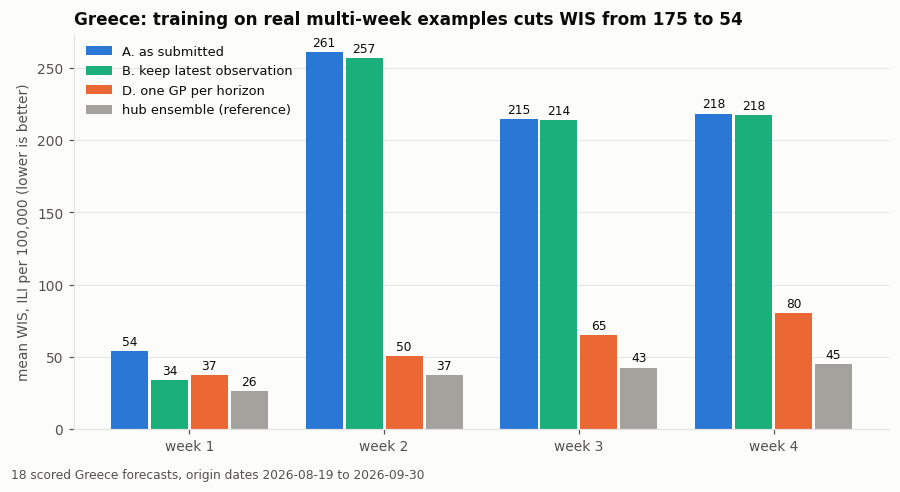

In [15]:
fig, ax = plt.subplots(figsize=(8.2, 4.3))
series = [('A. as submitted', C_ICE), ('B. keep latest observation', C_LAST), ('D. one GP per horizon', C_FIX), ('respicast-hubEnsemble', C_OTHER)]
wbar = 0.19
for i, (name, col) in enumerate(series):
    vals = [fix_tbl.loc[name, f'WIS h{h}'] for h in (1, 2, 3, 4)]
    xs = np.arange(4) + (i - 1.5) * (wbar + 0.015)
    ax.bar(xs, vals, width=wbar, color=col, label=name.replace('respicast-hubEnsemble', 'hub ensemble (reference)'))
    for x_, v in zip(xs, vals):
        ax.text(x_, v + 4, f'{v:.0f}', ha='center', fontsize=8, color=INK)
ax.set_xticks(np.arange(4)); ax.set_xticklabels([f'week {h}' for h in (1, 2, 3, 4)]); ax.grid(axis='x', visible=False)
ax.set_ylabel('mean WIS, ILI per 100,000 (lower is better)')
a_all, d_all = fix_tbl.loc['A. as submitted', 'WIS all'], fix_tbl.loc['D. one GP per horizon', 'WIS all']
ax.set_title(f'Greece: training on real multi-week examples cuts WIS from {a_all:.0f} to {d_all:.0f}')
ax.legend(loc='upper left', fontsize=8.5)
fig.text(0.01, -0.02, f'{len(idx)} scored Greece forecasts, origin dates {idx.get_level_values(0).min()} to {idx.get_level_values(0).max()}', fontsize=8, color=MUTED)
plt.tight_layout(); show(fig, '4_greece_wis_by_variant')

Fixing only the dropped observation (B) improves week 1 and leaves weeks 2 to 4 as bad as before. Teaching the model real multi-week behaviour (C or D) removes the collapse. Two different constructions give nearly the same score, which points to the mechanism rather than to a lucky variant.

The fix brings Greece to about the level of the hub's quantile baseline. It does not reach the hub ensemble.

### Replay of the 2025/26 season

Seven late-summer origin dates are a narrow test. The cell below replays what variants A, B and D would have submitted for Greece on every hub origin date from October 2025, using the snapshot available at the time, and scores them against the other hub models.

In [16]:
replay_origins = sorted(o for o in fw.origin_date.unique() if '2025-10-01' <= o <= origins[-1])
rows, skipped = [], []
for od in replay_origins:
    out = run_origin(od, 'ABD')
    (rows.extend(out) if out else skipped.append(od))
replay = pd.DataFrame(rows)
print(f'{replay.origin_date.nunique()} origin dates replayed, {len(skipped)} skipped (no snapshot or Greece not up to date): {skipped}')
rs = replay.dropna(subset=['wis'])
rows = []
for key in 'ABD':
    s = rs[rs.variant == key].set_index(['origin_date', 'horizon']).wis
    s = s[hub_tbl.drop(columns=[MODEL], errors='ignore').reindex(s.index).notna().sum(axis=1) >= 3]
    ah = against_hub(s)
    rows.append({'variant': VARIANTS[key][0], **{f'WIS h{h}': s.xs(h, level='horizon').mean() for h in (1, 2, 3, 4)}, 'WIS all': s.mean(),
                 'rank_score': ah.rank_score.mean(), 'mean rank': ah['rank'].mean(), 'models': ah.n_models.mean(), 'times worst': int((ah.rank_score == 0).sum()), 'n': len(s)})
ridx = s.index
for m in ('respicast-hubEnsemble', 'respicast-quantileBaseline'):
    hs = hub_tbl[m].reindex(ridx)
    rows.append({'variant': m, **{f'WIS h{h}': hs.xs(h, level='horizon').mean() for h in (1, 2, 3, 4)}, 'WIS all': hs.mean(), 'n': int(hs.notna().sum())})
replay_tbl = pd.DataFrame(rows).set_index('variant')
replay_tbl.to_csv(f'{ROOT}/results/greece_variants_replay.csv')
summary['replay'] = json.loads(replay_tbl.reset_index().to_json(orient='records'))
a_w = replay[(replay.variant == 'A') & (replay.horizon == 1)].set_index('origin_date').weight_h2
summary['replay_n_origins'] = int(replay.origin_date.nunique())
summary['replay_collapsed'] = int((a_w < 0.5).sum())
print(f"production fit collapses to the long-run mean (kernel weight at week 2 below 0.5) on {summary['replay_collapsed']} of {len(a_w)} replayed origin dates")
a_means = replay[replay.variant == 'A'].pivot(index='origin_date', columns='horizon', values='mean')
a_flat = (a_means.max(axis=1) - a_means.min(axis=1)) < 1e-6 * a_means[1].abs().clip(lower=1)
summary['replay_flat'] = int(a_flat.sum())
print(f"production forecast is the same number for all four weeks on {summary['replay_flat']} of {len(a_flat)} replayed origin dates")
replay_tbl

39 origin dates replayed, 15 skipped (no snapshot or Greece not up to date): ['2025-12-31', '2026-01-07', '2026-04-08', '2026-05-20', '2026-06-03', '2026-06-10', '2026-06-17', '2026-06-24', '2026-07-01', '2026-07-08', '2026-07-15', '2026-07-22', '2026-07-29', '2026-08-05', '2026-09-02']
production fit collapses to the long-run mean (kernel weight at week 2 below 0.5) on 8 of 39 replayed origin dates
production forecast is the same number for all four weeks on 0 of 39 replayed origin dates


,WIS h1,WIS h2,WIS h3,WIS h4,WIS all,rank_score,mean rank,models,times worst,n
variant,,,,,,,,,,
A. as submitted,90.620,163.304,190.210,223.086,165.352,0.569,10.493,17.233,25.0,146
B. keep latest observation,64.733,137.975,163.572,193.334,138.495,0.639,9.555,17.233,13.0,146
D. one GP per horizon,65.441,97.093,130.327,148.794,109.444,0.714,9.432,17.233,3.0,146
respicast-hubEnsemble,46.546,70.506,98.151,118.455,82.581,NaN,NaN,NaN,NaN,146
respicast-quantileBaseline,58.009,93.585,129.909,158.519,108.849,NaN,NaN,NaN,NaN,146


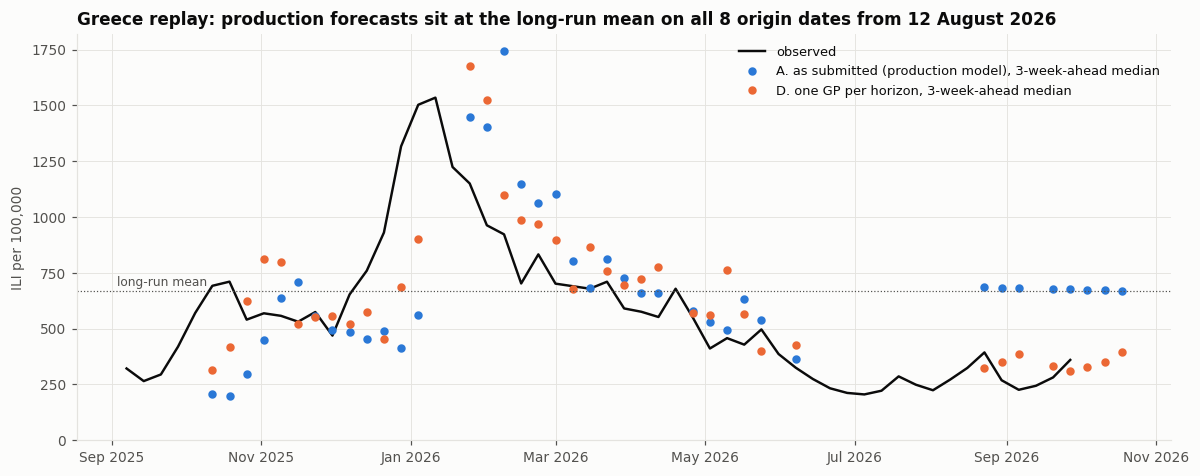

origin_date,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-08,2026-09,2026-10
collapsed,0,0,0,0,0,0,0,0,3,4,1
origin dates,5,4,4,3,4,4,4,3,3,4,1


In [17]:
h = 3
fig, ax = plt.subplots(figsize=(11, 4.4))
t = truth[truth.index >= '2025-09-01']
ax.plot(pd.to_datetime(t.index), t.values, color=INK, lw=1.6, label='observed')
for key, col, lab in (('A', C_ICE, 'A. as submitted (production model)'), ('D', C_FIX, 'D. one GP per horizon')):
    s = replay[(replay.variant == key) & (replay.horizon == h)]
    ax.plot(pd.to_datetime(s.target_end_date), s['mean'], color=col, lw=0, marker='o', ms=4.5, label=f'{lab}, {h}-week-ahead median')
ax.axhline(truth.mean(), color=MUTED, lw=0.8, ls=':'); ax.text(pd.Timestamp('2025-09-03'), truth.mean() + 25, 'long-run mean', fontsize=8, color=MUTED)
ax.set_ylabel('ILI per 100,000'); ax.set_ylim(0, None)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
first_c = a_w[a_w < 0.5].index.min(); since = a_w[a_w.index >= first_c]
summary['collapse_first_origin'] = first_c; summary['collapse_since_first'] = [int((since < 0.5).sum()), int(len(since))]
ax.set_title(f"Greece replay: production forecasts sit at the long-run mean on all {len(since)} origin dates from {pd.Timestamp(first_c).strftime('%-d %B %Y')}")
ax.legend(loc='upper right', fontsize=8.5)
plt.tight_layout(); show(fig, '5_greece_replay')

collapsed_by_month = (a_w < 0.5).groupby(pd.to_datetime(a_w.index).to_period('M')).agg(['sum', 'size']).rename(columns={'sum': 'collapsed', 'size': 'origin dates'})
collapsed_by_month.T

Over the whole season the production model is weak for Greece even before the collapse: its WIS is 1.5 times the hub baseline's (165 against 109). Restoring the dropped observation (B) recovers part of that. One GP per horizon (D) matches the hub baseline over the season (109) and is the worst model on 3 of 146 forecasts, against 25 for the production model. The hub ensemble (83) stays ahead of all three.

### Why the collapse started in August

The replay shows no collapse from October 2025 to May 2026 and a collapse on every origin date from 19 August. The model code did not change. The cell below looks at what did: the series the hub publishes for Greece.

In [18]:
rows = []
for od in sorted(replay.origin_date.unique()):
    d = snapshot_series(od, TARGET, LOC)
    vector, a, b, E = production_inputs(d)
    x = vector[a:b]
    start = np.sort(d.truth_date.to_numpy())[0]
    rows.append(dict(origin_date=od, series_start=start, weeks=len(x), missing_weeks=int(np.isnan(x).sum()), E=E,
                     blanked_week=(pd.Timestamp(start) + pd.Timedelta(weeks=20)).strftime('%Y-%m-%d'),
                     change_across_blank=x[21] - x[19], weight_h2=a_w[od]))
hist = pd.DataFrame(rows)
by_start = hist.groupby(['series_start', 'blanked_week']).agg(
    first_origin=('origin_date', 'min'), last_origin=('origin_date', 'max'), origin_dates=('origin_date', 'size'),
    weeks=('weeks', 'median'), change_across_blank=('change_across_blank', 'median'),
    collapsed=('weight_h2', lambda s: int((s < 0.5).sum()))).reset_index()
summary['series_start_history'] = json.loads(by_start.to_json(orient='records'))
print(by_start.to_string(index=False))

# cross-check on a snapshot from before the change: blank the same week (2022-11-13) in the longer May series
od_may = '2026-05-27'
d = snapshot_series(od_may, TARGET, LOC)
vector, a, b, E = production_inputs(d)
x = vector[a:b]
pos = int(round((pd.Timestamp('2022-11-13') - pd.Timestamp(np.sort(d.truth_date.to_numpy())[0])).days / 7))
r20, rnov = fit_production(x, E), fit_production(x, E, nan_at=pos)
print(f"\n{od_may} snapshot, blank at index 20 (production): weight at week 2 = {r20['weight'][1]:.3f}, forecasts {np.round(r20['predmean'])}")
print(f"{od_may} snapshot, blank moved to 2022-11-13 (index {pos}): weight at week 2 = {rnov['weight'][1]:.3f}, forecasts {np.round(rnov['predmean'])}")
summary['may_crosscheck'] = dict(weight_prod=float(r20['weight'][1]), weight_moved=float(rnov['weight'][1]), fc_prod=r20['predmean'].tolist(), fc_moved=rnov['predmean'].tolist())

series_start blanked_week first_origin last_origin  origin_dates  weeks  change_across_blank  collapsed
  2021-06-27   2021-11-14   2025-10-01  2026-05-27            31  238.0                -80.3          0
  2022-06-26   2022-11-13   2026-08-12  2026-10-07             8  218.5                330.6          8



2026-05-27 snapshot, blank at index 20 (production): weight at week 2 = 0.997, forecasts [424. 393. 363. 335.]
2026-05-27 snapshot, blank moved to 2022-11-13 (index 72): weight at week 2 = 0.015, forecasts [427. 831. 239. 609.]


The hub's Greece series became one year shorter between the May and August snapshots: it now starts on 26 June 2022, not 27 June 2021. The production code always blanks index 20, so the blanked week moved from 14 November 2021, where incidence changed by -80 across it, to 13 November 2022, where it rose by 331. All 8 replayed origin dates after the change collapse, and none of the 31 before it.

The cross-check confirms the trigger. In the longer May series, blanking 13 November 2022 in place of index 20 drops the week-2 kernel weight from 0.997 to 0.015 and produces erratic forecasts.

A likely reading: the single gap-2 row now spans a steep winter rise that the 1-week dynamics do not explain, and the optimiser accounts for it by making the time gap matter. The table in section 4 points the same way (large changes across the blanked week go with lower kernel weights), though not in proportion.

### The same variants on every submitted series

The dropped observation and the missing multi-week training rows are in the code path of every country. The cell below scores variants A, B and D for every series IceLab-EDM submitted since August. Variant D drops training rows that cross a reporting gap and needs the last E weeks to be present, so it is a first look, not a tuned replacement.

In [19]:
truth_by = {}
for t_ in ('ILI incidence', 'ARI incidence'):
    tt = pd.read_csv(f"{HUB}/target-data/latest-{t_.split()[0]}_incidence.csv")
    truth_by[t_] = tt.drop_duplicates(['location', 'truth_date']).set_index(['location', 'truth_date']).value
hub_all = wis_sc.pivot_table(index=['target', 'location', 'origin_date', 'horizon'], columns='model', values='value_absolute')

rows, failed = [], []
for _, s_ in ok.iterrows():
    od, tgt, loc = s_.origin_date, s_.target, s_.location
    h0, teds = horizon_dates(od)
    d = snapshot_series(od, tgt, loc)
    vector, a, b, E = production_inputs(d)
    for key in 'ABD':
        try:
            r = VARIANTS[key][1](vector, a, b, E)
            if not np.isfinite(r['predmean']).all() or not (r['predsd'] > 0).all():
                raise ValueError('no usable forecast')
        except Exception as e:
            failed.append((key, od, tgt, loc)); continue
        for h in range(4):
            y = truth_by[tgt].get((loc, teds[h]), np.nan)
            if y == y:
                rows.append(dict(target=tgt, location=loc, origin_date=od, horizon=h + 1, variant=key, wis=wis(r['predmean'][h], r['predsd'][h], y)))
allv = pd.DataFrame(rows)
wide = allv.pivot_table(index=['target', 'location', 'origin_date', 'horizon'], columns='variant', values='wis').dropna()
print(f"{len(wide)} scored forecasts with all three variants; failed fits: " + (', '.join(f'{k}: {sum(1 for f in failed if f[0] == k)}' for k in 'ABD')))

t = hub_all.drop(columns=[MODEL]).reindex(wide.index)
rsv = {}
for key in 'ABD':
    v = wide[key]; hi = np.maximum(t.max(axis=1), v); lo = np.minimum(t.min(axis=1), v)
    rsv[key] = (hi - v) / (hi - lo)
rsv = pd.DataFrame(rsv)
hub_ice = hub_all[MODEL].reindex(wide.index)
print(f"variant A against the hub's own IceLab-EDM WIS: median relative difference {np.nanmedian(np.abs(wide['A'] - hub_ice) / hub_ice):.1e}")
hz = wide.index.get_level_values('horizon')
all_tbl = pd.DataFrame({
    'rank score, week 1': rsv[hz == 1].mean(), 'rank score, weeks 2 to 4': rsv[hz >= 2].mean(), 'rank score, all': rsv.mean(),
    'median WIS ratio to A': wide.div(wide['A'], axis=0).median(), 'share of forecasts better than A': wide.lt(wide['A'], axis=0).mean(),
}).rename(index={k: VARIANTS[k][0] for k in 'ABD'})
all_tbl.to_csv(f'{ROOT}/results/all_series_variants.csv')
summary['all_series'] = json.loads(all_tbl.reset_index().to_json(orient='records')); summary['all_series_n'] = int(len(wide))
print(all_tbl.round(3).to_string())

by_series = rsv.groupby(['target', 'location']).mean().join(wide.groupby(['target', 'location']).size().rename('n'))
by_series['D minus A'] = by_series['D'] - by_series['A']
by_series.to_csv(f'{ROOT}/results/all_series_variants_by_series.csv')
by_series.sort_values('D minus A').round(2)

405 scored forecasts with all three variants; failed fits: A: 0, B: 0, D: 6
variant A against the hub's own IceLab-EDM WIS: median relative difference 6.8e-14
                            rank score, week 1  rank score, weeks 2 to 4  rank score, all  median WIS ratio to A  share of forecasts better than A
A. as submitted                          0.513                     0.561            0.545                  1.000                             0.000
B. keep latest observation               0.608                     0.599            0.602                  0.954                             0.704
D. one GP per horizon                    0.599                     0.608            0.605                  0.907                             0.583


A     B     D   n  D minus A
target        location                                 
ILI incidence SI        0.94  0.97  0.70   9      -0.24
ARI incidence EE        0.59  0.33  0.38  11      -0.21
ILI incidence LT        0.95  0.94  0.77  14      -0.17
              NO        0.67  0.68  0.54  18      -0.13
              BE        0.75  0.74  0.64  18      -0.10
ARI incidence LU        0.57  0.56  0.47  17      -0.10
              BG        0.32  0.34  0.25  18      -0.07
ILI incidence MT        0.82  0.74  0.75   7      -0.07
ARI incidence SI        0.43  0.49  0.38  18      -0.04
              HU        0.72  0.83  0.73  18       0.01
ILI incidence HU        0.71  0.76  0.72  18       0.01
              EE        0.78  0.77  0.80  11       0.02
ARI incidence IE        0.27  0.43  0.32  18       0.05
              NL        0.54  0.68  0.60  18       0.06
ILI incidence IE        0.68  0.75  0.75  18       0.07
              DK        0.70  0.79  0.77  18       0.07
ARI incidence CY        0.08  0.24  0.16   3       0.09
ILI incidence LU        0.58  0.68  0.68  13       0.10
ARI incidence ES        0.26  0.28  0.36  16       0.10
ILI incidence IS        0.61  0.61  0.72  17       0.11
              ES        0.82  0.92  0.94  16       0.11
ARI incidence DE        0.25  0.29  0.40  18       0.15
              BE        0.54  0.57  0.76  18       0.22
              LT        0.34  0.47  0.58  14       0.24
              IS        0.38  0.47  0.66  17       0.28
ILI incidence GR        0.20  0.27  0.65  18       0.45
              SK        0.01  0.56  0.63   3       0.62
ARI incidence SK        0.11  0.82  0.85   3       0.73

This is a low-season test only (origin dates 19 August to 30 September), so it says little about winter.

- **B, keep the newest observation:** better than the submitted forecast in 70% of the 405 scored forecasts. The week-1 rank score rises from 0.51 to 0.61. It is the same model with one more data point. Estonia ARI and Malta ILI are exceptions and score lower.
- **D, one GP per horizon:** not a uniform gain. It lifts Greece (+0.45), Slovakia, and the ARI series of Iceland, Lithuania, Belgium and Germany. It scores lower than the submitted model for Slovenia ILI, Estonia ARI, Lithuania ILI and Norway ILI. On average it equals B (0.60).
- The series where D loses are mostly ones where the submitted model repeats the week-1 number for all four weeks. In a flat low season that is hard to beat. Whether it holds through a winter is open; for Greece, the full-season replay favours D (rank score 0.71 against 0.64 for B).

In [20]:
with open(f'{ROOT}/results/summary.json', 'w') as f:
    json.dump(summary, f, indent=1, default=float)
fits.to_csv(f'{ROOT}/results/greece_variants_fits.csv', index=False)
replay.to_csv(f'{ROOT}/results/greece_replay_fits.csv', index=False)
print(json.dumps({k: v for k, v in summary.items() if not isinstance(v, (list, dict))}, indent=1, default=float))

{
 "gr_rank_score": 0.2016023354801473,
 "gr_n_scored": 18,
 "gr_times_worst": 10,
 "gr_n_models": 14,
 "gr_mean_wis": 174.62098275409852,
 "gr_series_mean": 668.4793721973095,
 "gr_recent_mean": 279.34999999999997,
 "repro_max_abs_diff": 2.6119550966541283e-11,
 "n_series_weeks": 172,
 "replay_n_origins": 39,
 "replay_collapsed": 8,
 "replay_flat": 0,
 "collapse_first_origin": "2026-08-12",
 "all_series_n": 405
}


## 7. Conclusions

**Why Greece is last**

1. The 0.2 is the mean WIS rank score over the 18 Greece forecasts scored since 19 August. IceLab-EDM is last of 14 models and the worst model in 10 of the 18. Its WIS is 1.5 times the median model's in week 1 and 3.4 to 4.9 times in weeks 2 to 4.
2. The 4-week forecast relies on a time-gap input that the training data cannot inform: 213 rows with gap 1, one artificial row with gap 2 (from `df1.iloc[20,1] = np.nan`), none with gaps 3 or 4. In the Greece fit the gap is treated as relevant, so the week 2 to 4 forecasts fall back to the GP prior: the series mean (about 675) with the series spread.
3. It started in August because the hub's Greece series lost its first year, which moved the blanked week onto the steep rise of November 2022.
4. The weakness is in every series. In 95 of 172 reproduced series-weeks the fit ignores the gap and submits the week-1 number four times. Only Greece collapses completely.

**A second bug, in every country**

5. `vector[minIdx:maxIdx-backPts]` drops the newest observation. The model's "week 1" is a forecast of the last observed week.

**What the tests say about fixes**

6. Keeping the newest observation improves 70% of all scored forecasts and lifts the week-1 rank score from 0.51 to 0.61. It does not fix Greece (0.20 to 0.27).
7. Training on real multi-week examples (one GP per horizon, or horizon as an input) removes the Greece collapse: WIS 175 to about 54, rank score 0.20 to 0.65. That is the level of the hub's quantile baseline (49), not of the ensemble (36).
8. Across all series one GP per horizon is mixed in the low season and equals the simpler fix on average. It needs a winter replay for all countries before it replaces the production model.

**Limits**

- The scored window is seven low-season origin dates. The season replay covers Greece only.
- Variants C and D are untuned, and D cannot forecast when one of the last E weeks is missing (6 series-weeks).
- Rank scores for the variants assume the other models' scores stay as they are.
- 9 of 181 series-weeks (Malta, Slovenia, Luxembourg and Croatia ILI) do not reproduce to 1e-6, and which ones varies between runs of this notebook. The cause is not investigated here; those series-weeks are left out of sections 5 and 6.